# Cross-Dataset Federated Learning for Floodwater Segmentation
### A Controlled Comparison of FedAvg, FedProx, FedNova and SCAFFOLD
**Authors:** Taha Ali, M. Usman, Umar Shoaib -- Department of Computer Science, FAST-NUCES, Lahore, Pakistan

---

This notebook is the **complete, self-contained experiment** for the paper. It trains one
common U-Net with four federated optimizers across three independently collected Sentinel-1
VV/VH flood datasets used as three non-IID clients, and produces every table and figure for
the **Experiments and Results** section.

| Client | Dataset | Coverage |
|---|---|---|
| Client 1 | **ETCI 2021** | Nebraska, N. Alabama, Bangladesh |
| Client 2 | **MMFlood** | 95 events, 42 countries (CEMS delineations) |
| Client 3 | **Kuro Siwo** | 43 events, permanent- vs flash-water separation |

**Controlled variables** (only the FL optimizer changes): U-Net + GroupNorm(8, $\varepsilon=10^{-5}$),
bilinear upsampling, $0.5$ masked-BCE $+\;0.5$ masked-Dice loss, SGD $\eta=0.01$, weight-decay $10^{-4}$,
grad-norm clip $5$, FedProx $\mu=0.01$, threshold $0.5$, identical initialization within a seed.


## 0. Running this notebook on Kaggle (free GPU session)

1. Open a new **Kaggle Notebook**, set **Settings -> Accelerator = GPU** (a ~9 h free quota).
2. Attach your reduced dataset (600 tiles total = 200 per client, already split into `train/val/test`,
   with sub-folders `etci/`, `mmflood/`, `kurosiwo/`) via **Add Input**. The notebook searches
   `/kaggle/input` recursively for the folder that contains `etci/train/images`.
3. **Run All.** Everything below trains the models and prints the results.

**Budget note.** The paper's full protocol is *100 rounds x 20 local steps x 3 seeds*. To fit a
single free GPU session we keep the same structure but use a **reduced dataset (200 tiles/client)**
and a smaller *rounds / local-steps / budget* (Section 3). All runs still execute in a small
fraction of the 9 h window; increase the values in Section 3 if more compute time is available.


## 1. Imports, Reproducibility and Device
Deterministic seeds, the PyTorch device, the dataset pipeline, the U-Net, the masked loss,
pixel-level metrics, the four FL client optimizers and the federated **Coordinator** are all
defined in this single self-contained cell.


In [6]:
import os, copy, time, json, random, glob
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, ConcatDataset
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import pandas as pd


def _show(df):
    """Render a DataFrame in-notebook when IPython is available, else print."""
    try:
        from IPython.display import display
        display(df)
    except Exception:
        print(df.to_string(index=False))


# ---------------------------------------------------------------------------
# Data path auto-detection (Kaggle mount or local folder)
# ---------------------------------------------------------------------------
def resolve_data_root(dataset_name='flood-federated-kaggle', folder='federated_kaggle'):
    """Find the folder that contains etci/, mmflood/, kurosiwo/ (any depth under /kaggle/input)."""
    # 1) explicit path first (edit this if Kaggle mounts your dataset elsewhere)
    explicit = '/kaggle/input/datasets/umarshoaib66/flood-area-detection-dataset'
    candidates = [explicit, explicit + '/' + folder, 'data/' + folder]
    # 2) otherwise search the whole input tree for  <root>/etci/train/images
    input_root = Path('/kaggle/input')
    if input_root.exists():
        for dirpath, dirnames, _ in os.walk(str(input_root)):
            if 'etci' in dirnames:
                candidates.append(dirpath)
    for path in candidates:
        if Path(path, 'etci', 'train', 'images').exists():
            print('[Data] Using data root:', path)
            return path
    tree = []
    if input_root.exists():
        for dirpath, dirnames, _ in os.walk(str(input_root)):
            depth = dirpath[len(str(input_root)):].count(os.sep)
            if depth <= 4:
                tree.append(dirpath)
    raise FileNotFoundError('Could not find <root>/etci/train/images. Folders under /kaggle/input:\n'
                            + '\n'.join(tree[:40]))


def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')


# ---------------------------------------------------------------------------
# Dataset & augmentation (Section III-C)
# ---------------------------------------------------------------------------
class FloodTileDataset(Dataset):
    def __init__(self, client_name, split='train', data_root='federated_kaggle', augment=False):
        self.augment = augment
        base = Path(data_root) / client_name / split
        self.img_paths = sorted(base.joinpath('images').glob('*.npy'))
        self.msk_paths = sorted(base.joinpath('masks').glob('*.npy'))
        assert len(self.img_paths) == len(self.msk_paths) and len(self.img_paths) > 0, \
            f'Image/mask mismatch or empty for {client_name}/{split}'

    def __len__(self):
        return len(self.img_paths)

    def __getitem__(self, idx):
        img = np.load(self.img_paths[idx]).astype(np.float32)   # (256,256,2) in [0,1]
        msk = np.load(self.msk_paths[idx]).astype(np.uint8)     # (256,256) in {0,1,255}
        img = img * 2.0 - 1.0                                    # map to [-1,1]
        if self.augment:
            if random.random() > 0.5:
                img, msk = np.fliplr(img).copy(), np.fliplr(msk).copy()
            if random.random() > 0.5:
                img, msk = np.flipud(img).copy(), np.flipud(msk).copy()
            k = random.choice([0, 1, 2, 3])
            if k > 0:
                img = np.rot90(img, k=k, axes=(0, 1)).copy()
                msk = np.rot90(msk, k=k, axes=(0, 1)).copy()
        img_t = torch.from_numpy(np.transpose(img, (2, 0, 1))).float()
        msk_t = torch.from_numpy(msk).long()
        return img_t, msk_t


# ---------------------------------------------------------------------------
# U-Net with GroupNorm + bilinear upsampling + bottleneck dropout (Section III-B)
# ---------------------------------------------------------------------------
class DoubleConv(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1, bias=False),
            nn.GroupNorm(8, out_ch, eps=1e-5), nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False),
            nn.GroupNorm(8, out_ch, eps=1e-5), nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.conv(x)


class FloodUNet(nn.Module):
    def __init__(self, in_channels=2, num_classes=1):
        super().__init__()
        self.enc1 = DoubleConv(in_channels, 32); self.pool1 = nn.MaxPool2d(2)
        self.enc2 = DoubleConv(32, 64);           self.pool2 = nn.MaxPool2d(2)
        self.enc3 = DoubleConv(64, 128);          self.pool3 = nn.MaxPool2d(2)
        self.enc4 = DoubleConv(128, 256);         self.pool4 = nn.MaxPool2d(2)
        self.bottleneck = DoubleConv(256, 512)
        self.dropout = nn.Dropout2d(0.1)
        self.up4 = nn.Upsample(scale_factor=2, mode='bilinear', align_corners=False)
        self.dec4 = DoubleConv(512 + 256, 256)
        self.up3 = nn.Upsample(scale_factor=2, mode='bilinear', align_corners=False)
        self.dec3 = DoubleConv(256 + 128, 128)
        self.up2 = nn.Upsample(scale_factor=2, mode='bilinear', align_corners=False)
        self.dec2 = DoubleConv(128 + 64, 64)
        self.up1 = nn.Upsample(scale_factor=2, mode='bilinear', align_corners=False)
        self.dec1 = DoubleConv(64 + 32, 32)
        self.head = nn.Conv2d(32, num_classes, 1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool1(e1))
        e3 = self.enc3(self.pool2(e2))
        e4 = self.enc4(self.pool3(e3))
        b = self.dropout(self.bottleneck(self.pool4(e4)))
        d4 = self.dec4(torch.cat([self.up4(b), e4], 1))
        d3 = self.dec3(torch.cat([self.up3(d4), e3], 1))
        d2 = self.dec2(torch.cat([self.up2(d3), e2], 1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], 1))
        return self.head(d1)


# ---------------------------------------------------------------------------
# Masked 0.5 BCE + 0.5 Soft-Dice loss (Eq. 1)
# ---------------------------------------------------------------------------
class MaskedBCEAndDiceLoss(nn.Module):
    def __init__(self, ignore_index=255, eps=1e-6):
        super().__init__()
        self.ignore_index = ignore_index
        self.eps = eps

    def forward(self, logits, targets):
        targets_f = targets.unsqueeze(1).float()
        valid = (targets != self.ignore_index).unsqueeze(1).bool()
        if not valid.any():
            return torch.tensor(0.0, device=logits.device, requires_grad=True)
        vl, vt = logits[valid], targets_f[valid]
        bce = F.binary_cross_entropy_with_logits(vl, vt)
        probs = torch.sigmoid(logits)
        pv = probs * valid.float()
        tv = targets_f * valid.float()
        inter = torch.sum(pv * tv)
        card = torch.sum(pv) + torch.sum(tv)
        if torch.sum(tv) == 0:
            return bce
        dice = 1.0 - (2.0 * inter + self.eps) / (card + self.eps)
        return 0.5 * bce + 0.5 * dice


# ---------------------------------------------------------------------------
# Pixel-level metric accumulation (Eq. 3-4)
# ---------------------------------------------------------------------------
class MetricTracker:
    def __init__(self):
        self.reset()

    def reset(self):
        self.tp = self.fp = self.fn = self.tn = 0

    def update(self, preds, targets, ignore_index=255):
        preds = preds.squeeze(1).bool().cpu().numpy()
        targets = targets.cpu().numpy()
        valid = targets != ignore_index
        p_v, t_v = preds[valid], (targets[valid] == 1)
        self.tp += int(np.sum(p_v & t_v))
        self.fn += int(np.sum((~p_v) & t_v))
        self.fp += int(np.sum(p_v & (~t_v)))
        self.tn += int(np.sum((~p_v) & (~t_v)))

    def compute(self):
        tp, fp, fn, tn = self.tp, self.fp, self.fn, self.tn
        total = tp + fp + fn + tn
        return {
            'iou': float(tp / (tp + fp + fn)) if (tp + fp + fn) > 0 else 0.0,
            'dice': float(2.0 * tp / (2.0 * tp + fp + fn)) if (2.0 * tp + fp + fn) > 0 else 0.0,
            'precision': float(tp / (tp + fp)) if (tp + fp) > 0 else 0.0,
            'recall': float(tp / (tp + fn)) if (tp + fn) > 0 else 0.0,
            'accuracy': float((tp + tn) / total) if total > 0 else 0.0,
            'tp': tp, 'fp': fp, 'fn': fn, 'tn': tn,
        }


def get_params(model):
    return {k: v.cpu().clone() for k, v in model.state_dict().items()}


def set_params(model, params):
    model.load_state_dict(params)


def fed_average(client_params, weights):
    out = {}
    for k in client_params[0]:
        out[k] = sum(client_params[i][k] * weights[i] for i in range(len(client_params)))
    return out


class InfiniteDataLoader:
    def __init__(self, loader):
        self.loader = loader
        self.it = iter(loader)

    def next_batch(self):
        try:
            return next(self.it)
        except StopIteration:
            self.it = iter(self.loader)
            return next(self.it)


# ---------------------------------------------------------------------------
# Federated client with FedAvg / FedProx / SCAFFOLD local updates (Section III-D)
# ---------------------------------------------------------------------------
class FLClient:
    def __init__(self, name, data_root, batch_size=8, lr=0.01, weight_decay=1e-4, grad_clip=5.0):
        self.name = name
        self.batch_size, self.lr, self.weight_decay, self.grad_clip = batch_size, lr, weight_decay, grad_clip
        self.loss_fn = MaskedBCEAndDiceLoss()
        self.train_ds = FloodTileDataset(name, 'train', data_root, augment=True)
        self.val_ds = FloodTileDataset(name, 'val', data_root, augment=False)
        self.test_ds = FloodTileDataset(name, 'test', data_root, augment=False)
        self.num_train = len(self.train_ds)
        pin = DEVICE.type == 'cuda'
        self.train_loader = DataLoader(self.train_ds, batch_size=batch_size, shuffle=True, drop_last=True, num_workers=0, pin_memory=pin)
        self.val_loader = DataLoader(self.val_ds, batch_size=batch_size, shuffle=False, num_workers=0)
        self.test_loader = DataLoader(self.test_ds, batch_size=batch_size, shuffle=False, num_workers=0)
        self.train_iter = InfiniteDataLoader(self.train_loader)
        self.c_i = None

    def init_scaffold(self, model):
        self.c_i = {k: torch.zeros_like(v, device=DEVICE) for k, v in model.named_parameters()}

    def _train_step(self, model, optimizer, imgs, masks):
        imgs, masks = imgs.to(DEVICE, non_blocking=True), masks.to(DEVICE, non_blocking=True)
        optimizer.zero_grad()
        loss = self.loss_fn(model(imgs), masks)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), self.grad_clip)
        return loss

    def train_fedavg(self, model, num_steps):
        model.train()
        opt = torch.optim.SGD(model.parameters(), lr=self.lr, weight_decay=self.weight_decay)
        tot, done = 0.0, 0
        while done < num_steps:
            imgs, masks = self.train_iter.next_batch()
            if not (masks != 255).any():
                continue
            loss = self._train_step(model, opt, imgs, masks)
            opt.step()
            tot += loss.item()
            done += 1
        return tot / max(1, done)

    def train_fedprox(self, model, global_params, num_steps, mu=0.01):
        model.train()
        opt = torch.optim.SGD(model.parameters(), lr=self.lr, weight_decay=self.weight_decay)
        gp = {k: v.to(DEVICE) for k, v in global_params.items()}
        tot, done = 0.0, 0
        while done < num_steps:
            imgs, masks = self.train_iter.next_batch()
            if not (masks != 255).any():
                continue
            model.train()
            opt.zero_grad()
            logits = model(imgs.to(DEVICE, non_blocking=True))
            base = self.loss_fn(logits, masks.to(DEVICE, non_blocking=True))
            prox = sum(((p - gp[n]) ** 2).sum() for n, p in model.named_parameters() if n in gp)
            loss = base + 0.5 * mu * prox
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), self.grad_clip)
            opt.step()
            tot += loss.item()
            done += 1
        return tot / max(1, done)

    def train_scaffold(self, model, c_global, num_steps):
        model.train()
        opt = torch.optim.SGD(model.parameters(), lr=self.lr, weight_decay=self.weight_decay)
        if self.c_i is None:
            self.init_scaffold(model)
        init = {k: v.clone().detach() for k, v in model.named_parameters()}
        tot, done = 0.0, 0
        while done < num_steps:
            imgs, masks = self.train_iter.next_batch()
            if not (masks != 255).any():
                continue
            loss = self._train_step(model, opt, imgs, masks)  # fills .grad
            with torch.no_grad():
                for n, p in model.named_parameters():
                    if p.grad is not None:
                        p.grad.add_(-self.c_i[n] + c_global[n])
            opt.step()
            tot += loss.item()
            done += 1
        delta_c = {}
        with torch.no_grad():
            for n, p in model.named_parameters():
                new_c = self.c_i[n] - c_global[n] + (1.0 / (num_steps * self.lr)) * (init[n] - p.data)
                delta_c[n] = new_c - self.c_i[n]
                self.c_i[n] = new_c
        return tot / max(1, done), delta_c


class Coordinator:
    def __init__(self, data_root, clients=('etci', 'mmflood', 'kurosiwo'), batch_size=8, lr=0.01, fedprox_mu=0.01):
        self.data_root = data_root
        self.trained = {}
        self.client_names = list(clients)
        self.batch_size, self.lr, self.mu = batch_size, lr, fedprox_mu
        self.clients = {n: FLClient(n, data_root, batch_size=batch_size, lr=lr) for n in self.client_names}
        total = sum(c.num_train for c in self.clients.values())
        self.weights = [self.clients[n].num_train / total for n in self.client_names]
        print('[Coordinator] clients =', self.client_names,
              '| tiles =', [self.clients[n].num_train for n in self.client_names],
              '| weights =', [round(w, 4) for w in self.weights])

    def _eval(self, model, loader, max_batches=None):
        model.eval()
        tr = MetricTracker()
        with torch.no_grad():
            for i, (imgs, tg) in enumerate(loader):
                if max_batches is not None and i >= max_batches:
                    break
                logits = model(imgs.to(DEVICE))
                tr.update((torch.sigmoid(logits) >= 0.5), tg)
        return tr.compute()

    def eval_val(self, model):
        per = {n: self._eval(model, self.clients[n].val_loader)['iou'] for n in self.client_names}
        return float(np.mean(list(per.values()))), per

    def eval_test(self, model):
        per = {n: self._eval(model, self.clients[n].test_loader) for n in self.client_names}
        pooled = MetricTracker()
        pooled.tp = sum(per[n]['tp'] for n in per)
        pooled.fp = sum(per[n]['fp'] for n in per)
        pooled.fn = sum(per[n]['fn'] for n in per)
        pooled.tn = sum(per[n]['tn'] for n in per)
        macro = {m: float(np.mean([per[n][m] for n in self.client_names]))
                 for m in ('iou', 'dice', 'precision', 'recall', 'accuracy')}
        return {'per_client': per, 'macro': macro, 'pooled': pooled.compute()}

    def run_federated(self, algorithm, num_rounds=15, local_steps=10, seed=42, patience=15):
        set_seed(seed)
        g = FloodUNet().to(DEVICE)
        c_global = None
        if algorithm == 'scaffold':
            c_global = {k: torch.zeros_like(v, device=DEVICE) for k, v in g.named_parameters()}
            for cl in self.clients.values():
                cl.init_scaffold(g)
        steps_list = local_steps if isinstance(local_steps, list) else [local_steps] * len(self.client_names)

        best_iou, best_round, best_state, no_imp = -1.0, 0, copy.deepcopy(g.state_dict()), 0
        history = []
        t0 = time.time()
        print(f'\n--- {algorithm.upper()} (seed={seed}, rounds<={num_rounds}, steps={steps_list}) ---', flush=True)
        for r in range(1, num_rounds + 1):
            states, losses, deltas = [], {}, []
            for i, name in enumerate(self.client_names):
                cl = self.clients[name]
                lm = copy.deepcopy(g)
                if algorithm in ('fedavg', 'fednova'):
                    losses[name] = cl.train_fedavg(lm, steps_list[i])
                elif algorithm == 'fedprox':
                    losses[name] = cl.train_fedprox(lm, g.state_dict(), steps_list[i], mu=self.mu)
                elif algorithm == 'scaffold':
                    losses[name], dc = cl.train_scaffold(lm, c_global, steps_list[i])
                    deltas.append(dc)
                else:
                    raise ValueError(algorithm)
                states.append(get_params(lm))

            if algorithm in ('fedavg', 'fedprox'):
                set_params(g, fed_average(states, self.weights))
            elif algorithm == 'fednova':
                a_eff = sum(self.weights[i] * steps_list[i] for i in range(len(steps_list)))
                gs = g.state_dict()
                newp = {}
                for k in gs:
                    if gs[k].dtype.is_floating_point:
                        d = sum(self.weights[i] * (gs[k].cpu() - states[i][k]) / float(steps_list[i])
                                for i in range(len(states)))
                        newp[k] = gs[k].cpu() - a_eff * d
                    else:
                        newp[k] = states[0][k]
                set_params(g, newp)
            elif algorithm == 'scaffold':
                set_params(g, fed_average(states, self.weights))
                with torch.no_grad():
                    for k in c_global:
                        c_global[k].add_(sum(deltas[i][k] for i in range(len(deltas))) / len(deltas))

            macro_iou, per_iou = self.eval_val(g)
            history.append({'round': r, 'macro_val_iou': macro_iou, 'per_val': per_iou,
                            'train_loss': losses, 'round_time': time.time() - t0})
            print(f'Round {r:02d}: Macro Val IoU={macro_iou:.4f} | ' +
                  ', '.join(f'{n}:{per_iou[n]:.4f}' for n in self.client_names), flush=True)
            if macro_iou > best_iou:
                best_iou, best_round, no_imp = macro_iou, r, 0
                best_state = copy.deepcopy(g.state_dict())
            else:
                no_imp += 1
                if no_imp >= patience:
                    print(f'Early stop @ round {r}', flush=True)
                    break

        total_time = time.time() - t0
        g.load_state_dict(best_state)
        test = self.eval_test(g)
        self.trained[(algorithm, seed)] = copy.deepcopy(g.state_dict())
        return {'algorithm': algorithm, 'seed': seed, 'best_round': best_round,
                'best_val_iou': best_iou, 'test': test, 'history': history,
                'time': total_time, 'rounds_run': len(history)}

    def run_centralized(self, max_steps=300, check_interval=30, seed=42, patience=15):
        set_seed(seed)
        m = FloodUNet().to(DEVICE)
        pooled = ConcatDataset([self.clients[n].train_ds for n in self.client_names])
        it = InfiniteDataLoader(DataLoader(pooled, batch_size=self.batch_size, shuffle=True, drop_last=True, num_workers=0))
        opt = torch.optim.SGD(m.parameters(), lr=self.lr, weight_decay=1e-4)
        loss_fn = MaskedBCEAndDiceLoss()
        best, bstep, bstate, no_imp, hist = -1.0, 0, copy.deepcopy(m.state_dict()), 0, []
        t0 = time.time()
        print(f'\n--- CENTRALIZED (seed={seed}, max_steps={max_steps}) ---', flush=True)
        for s in range(1, max_steps + 1):
            imgs, masks = it.next_batch()
            if not (masks != 255).any():
                continue
            m.train()
            opt.zero_grad()
            l = loss_fn(m(imgs.to(DEVICE)), masks.to(DEVICE))
            l.backward()
            torch.nn.utils.clip_grad_norm_(m.parameters(), 5.0)
            opt.step()
            if s % check_interval == 0:
                mi, per = self.eval_val(m)
                hist.append({'step': s, 'round': s / check_interval, 'macro_val_iou': mi, 'per_val': per})
                print(f'Step {s:03d}: Macro Val IoU={mi:.4f}', flush=True)
                if mi > best:
                    best, bstep, no_imp = mi, s, 0
                    bstate = copy.deepcopy(m.state_dict())
                else:
                    no_imp += 1
                    if no_imp >= patience:
                        break
        tt = time.time() - t0
        m.load_state_dict(bstate)
        test = self.eval_test(m)
        self.trained[('centralized', seed)] = copy.deepcopy(m.state_dict())
        return {'algorithm': 'centralized', 'seed': seed, 'best_step': bstep,
                'best_val_iou': best, 'test': test, 'history': hist, 'time': tt,
                'rounds_run': len(hist)}

    def run_local(self, name, max_steps=150, check_interval=30, seed=42, patience=15):
        set_seed(seed)
        m = FloodUNet().to(DEVICE)
        cl = self.clients[name]
        it = cl.train_iter
        opt = torch.optim.SGD(m.parameters(), lr=self.lr, weight_decay=1e-4)
        loss_fn = MaskedBCEAndDiceLoss()
        best, bstep, bstate, no_imp, hist = -1.0, 0, copy.deepcopy(m.state_dict()), 0, []
        t0 = time.time()
        print(f'\n--- LOCAL-ONLY [{name.upper()}] (seed={seed}) ---', flush=True)
        for s in range(1, max_steps + 1):
            imgs, masks = it.next_batch()
            if not (masks != 255).any():
                continue
            m.train()
            opt.zero_grad()
            l = loss_fn(m(imgs.to(DEVICE)), masks.to(DEVICE))
            l.backward()
            torch.nn.utils.clip_grad_norm_(m.parameters(), 5.0)
            opt.step()
            if s % check_interval == 0:
                vi = self._eval(m, cl.val_loader)['iou']
                hist.append({'step': s, 'round': s / check_interval, 'val_iou': vi})
                if vi > best:
                    best, bstep, no_imp = vi, s, 0
                    bstate = copy.deepcopy(m.state_dict())
                else:
                    no_imp += 1
                    if no_imp >= patience:
                        break
        tt = time.time() - t0
        m.load_state_dict(bstate)
        test = self.eval_test(m)
        self.trained[(f'local_{name}', seed)] = copy.deepcopy(m.state_dict())
        return {'algorithm': f'local_{name}', 'seed': seed, 'client': name, 'best_step': bstep,
                'best_val_iou': best, 'test': test, 'history': hist, 'time': tt,
                'rounds_run': len(hist)}


# ---------------------------------------------------------------------------
# Result aggregation across seeds -> mean (+/- std) tables
# ---------------------------------------------------------------------------
FL_METHODS = [('FedAvg', 'fedavg'), ('FedProx', 'fedprox'), ('FedNova', 'fednova'),
              ('SCAFFOLD', 'scaffold'), ('Centralized', 'centralized'),
              ('Local ETCI', 'local_etci'), ('Local MMFlood', 'local_mmflood'),
              ('Local Kuro Siwo', 'local_kurosiwo')]


def _collect(runs, key):
    return [r['test']['per_client'][key]['iou'] for r in runs if key in r['test']['per_client']]


def summarize_federated(results):
    rows = []
    for label, key in FL_METHODS:
        if key not in results:
            continue
        runs = results[key]
        macro = [r['test']['macro'] for r in runs]
        per = {n: _collect(runs, n) for n in ('etci', 'mmflood', 'kurosiwo')}
        rows.append({
            'Method': label,
            'ETCI IoU': np.mean(per['etci']),
            'MMFlood IoU': np.mean(per['mmflood']),
            'KuroSiwo IoU': np.mean(per['kurosiwo']),
            'Macro IoU': np.mean([m['iou'] for m in macro]),
            'Macro IoU std': np.std([m['iou'] for m in macro]),
            'Macro Dice': np.mean([m['dice'] for m in macro]),
            'Macro Precision': np.mean([m['precision'] for m in macro]),
            'Macro Recall': np.mean([m['recall'] for m in macro]),
            'Pooled IoU': np.mean([r['test']['pooled']['iou'] for r in runs]),
            'Seeds': len(runs),
        })
    return pd.DataFrame(rows)


def fmt(df, cols, prec=3):
    out = df.copy()
    for c in cols:
        if c in out.columns:
            out[c] = out[c].map(lambda x: f'{x:.{prec}f}')
    return out


def cross_domain_table(results):
    rows = []
    for label, key in FL_METHODS:
        if not key.startswith('local_'):
            continue
        runs = results[key]
        home = key.replace('local_', '')
        vals = {}
        for n in ('etci', 'mmflood', 'kurosiwo'):
            vals[n] = np.mean(_collect(runs, n))
        rows.append({'Model (trained on)': label,
                     'In-domain IoU': vals[home],
                     'ETCI IoU': vals['etci'], 'MMFlood IoU': vals['mmflood'],
                     'KuroSiwo IoU': vals['kurosiwo'],
                     'Macro Cross-domain IoU': np.mean([v for k, v in vals.items() if k != home])})
    return pd.DataFrame(rows)


def compute_profile(coordinator):
    m = FloodUNet().to(DEVICE)
    params = sum(p.numel() for p in m.parameters() if p.requires_grad)
    ckpt_mb = sum(p.numel() * p.element_size() for p in m.parameters()) / (1024 ** 2)
    n_clients = len(coordinator.client_names)
    comm_up_mb = ckpt_mb * n_clients
    comm_round_mb = ckpt_mb * 2 * n_clients
    scaffold_round_mb = ckpt_mb * 4 * n_clients
    test = coordinator.clients[coordinator.client_names[0]].test_loader
    imgs = next(iter(test))[0].to(DEVICE)
    m.eval()
    with torch.no_grad():
        m(imgs)
        if DEVICE.type == 'cuda':
            torch.cuda.synchronize()
        t0 = time.time()
        bs = imgs.shape[0]
        reps = 20
        for _ in range(reps):
            m(imgs)
        if DEVICE.type == 'cuda':
            torch.cuda.synchronize()
        infer_ms = (time.time() - t0) / reps / bs * 1000
    return {'trainable_params': params, 'ckpt_mb': ckpt_mb, 'n_clients': n_clients,
            'comm_up_mb': comm_up_mb, 'comm_round_mb': comm_round_mb,
            'scaffold_round_mb': scaffold_round_mb, 'infer_ms_per_tile': infer_ms}


### 1b. Visualization utilities
All result figures (convergence, per-client bars, unequal-work comparison, pixel confusion
matrices, qualitative predictions and error decomposition) are defined here as plain functions,
so the notebook stays self-contained.


In [7]:
# ---------------------------------------------------------------------------
# Visualization helpers (all figures written to the notebook working dir)
# ---------------------------------------------------------------------------
FIG_COLORS = {'fedavg': '#1f77b4', 'fedprox': '#ff7f0e', 'fednova': '#2ca02c',
              'scaffold': '#d62728', 'centralized': '#9467bd'}
FIG_LABELS = {'fedavg': 'FedAvg', 'fedprox': 'FedProx ($\\mu$=0.01)', 'fednova': 'FedNova',
              'scaffold': 'SCAFFOLD', 'centralized': 'Centralized (pooled upper bound)'}


def _mean_curve(runs):
    buckets = {}
    for r in runs:
        for h in r['history']:
            rd = int(round(h['round']))
            buckets.setdefault(rd, []).append(h['macro_val_iou'])
    xs = sorted(buckets)
    return xs, [float(np.mean(buckets[x])) for x in xs]


def plot_convergence(results, save_path='fig1_val_convergence.png'):
    plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
    fig, ax = plt.subplots(figsize=(7.5, 4.5), dpi=150)
    order = ['fedavg', 'fedprox', 'fednova', 'scaffold', 'centralized']
    for key in order:
        if key not in results:
            continue
        xs, ys = _mean_curve(results[key])
        style = '--' if key == 'centralized' else '-'
        ax.plot(xs, ys, style, marker='o', ms=4, lw=2, color=FIG_COLORS[key], label=FIG_LABELS[key])
    ax.set_xlabel('Communication Rounds (centralized: equivalent work)', fontsize=11, fontweight='bold')
    ax.set_ylabel('Macro Validation Flood IoU', fontsize=11, fontweight='bold')
    ax.set_title('Fig. 1 - Validation Convergence (mean over seeds)', fontsize=12, fontweight='bold')
    ax.legend(loc='lower right', fontsize=9, frameon=True)
    ax.set_ylim(0, 1.0)
    plt.tight_layout(); plt.savefig(save_path, bbox_inches='tight'); plt.close()
    return save_path


def plot_per_client(results, save_path='fig2_per_client_performance.png'):
    clients = ['etci', 'mmflood', 'kurosiwo']
    names = ['ETCI 2021', 'MMFlood', 'Kuro Siwo']
    methods = ['fedavg', 'fedprox', 'fednova', 'scaffold', 'centralized']
    x = np.arange(len(clients)); w = 0.15
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.6), dpi=150)
    for i, m in enumerate(methods):
        if m not in results:
            continue
        ious = [np.mean(_collect(results[m], c)) for c in clients]
        dics = [np.mean([r['test']['per_client'][c]['dice'] for r in results[m]]) for c in clients]
        off = (i - len(methods) / 2 + 0.5) * w
        a1.bar(x + off, ious, w, label=FIG_LABELS[m], color=FIG_COLORS[m], edgecolor='black', lw=0.4)
        a2.bar(x + off, dics, w, label=FIG_LABELS[m], color=FIG_COLORS[m], edgecolor='black', lw=0.4)
    for ax, ttl, ylab in ((a1, 'Test Flood IoU', 'IoU'), (a2, 'Test Flood Dice / F1', 'Dice')):
        ax.set_title(ttl, fontsize=11, fontweight='bold'); ax.set_xticks(x)
        ax.set_xticklabels(names, fontsize=9, fontweight='bold'); ax.set_ylabel(ylab)
        ax.set_ylim(0, 1.0); ax.grid(axis='y', ls='--', alpha=0.6)
    a2.legend(fontsize=8, loc='upper left', bbox_to_anchor=(1.01, 1))
    fig.suptitle('Fig. 2 - Per-Client Test Performance (mean over seeds)', fontsize=12, fontweight='bold')
    plt.tight_layout(); plt.savefig(save_path, bbox_inches='tight'); plt.close()
    return save_path


def plot_unequal(equal_res, unequal_res, save_path='fig3_unequal_computation.png'):
    algos = ['fedavg', 'fedprox', 'fednova', 'scaffold']
    eq = [np.mean([r['test']['macro']['iou'] for r in equal_res.get(a, [])]) for a in algos]
    un = [np.mean([r['test']['macro']['iou'] for r in unequal_res.get(a, [])]) for a in algos]
    x = np.arange(len(algos)); w = 0.36
    fig, ax = plt.subplots(figsize=(7.5, 4.5), dpi=150)
    ax.bar(x - w / 2, eq, w, label='Equal steps (10,10,10)', color='#3470a3', edgecolor='black', lw=0.5)
    ax.bar(x + w / 2, un, w, label='Unequal steps (5,10,15)', color='#d95f02', edgecolor='black', lw=0.5)
    ax.set_xticks(x); ax.set_xticklabels([FIG_LABELS[a] for a in algos], fontsize=10, fontweight='bold')
    ax.set_ylabel('Macro Test Flood IoU', fontsize=11, fontweight='bold'); ax.set_ylim(0, 1.0)
    ax.set_title('Fig. 3 - Robustness to Unequal Local Computation', fontsize=12, fontweight='bold')
    ax.legend(fontsize=9); ax.grid(axis='y', ls='--', alpha=0.6)
    plt.tight_layout(); plt.savefig(save_path, bbox_inches='tight'); plt.close()
    return save_path


def plot_confusion_matrices(results, save_path='fig4_confusion_matrices.png'):
    methods = ['fedavg', 'fedprox', 'fednova', 'scaffold', 'centralized']
    methods = [m for m in methods if m in results]
    fig, axes = plt.subplots(1, len(methods), figsize=(3.1 * len(methods), 3.4), dpi=150)
    axes = np.atleast_1d(axes)
    for ax, m in zip(axes, methods):
        tp = np.mean([r['test']['pooled']['tp'] for r in results[m]])
        fp = np.mean([r['test']['pooled']['fp'] for r in results[m]])
        fn = np.mean([r['test']['pooled']['fn'] for r in results[m]])
        tn = np.mean([r['test']['pooled']['tn'] for r in results[m]])
        conf = np.array([[tn, fp], [fn, tp]], dtype=float)
        rowsum = conf.sum(1, keepdims=True); rowsum[rowsum == 0] = 1
        pct = conf / rowsum * 100.0
        im = ax.imshow(pct, cmap='Blues', vmin=0, vmax=100)
        ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
        ax.set_xticklabels(['Non-Flood', 'Flood'], fontsize=8); ax.set_yticklabels(['Non-Flood', 'Flood'], fontsize=8)
        ax.set_xlabel('Predicted', fontsize=9); ax.set_ylabel('Ground Truth', fontsize=9)
        ax.set_title(FIG_LABELS[m].split(' (')[0], fontsize=10, fontweight='bold')
        for i in range(2):
            for j in range(2):
                ax.text(j, i, f'{pct[i, j]:.1f}%', ha='center', va='center',
                        color='white' if pct[i, j] > 55 else 'black', fontsize=9)
    fig.suptitle('Fig. 4 - Pixel-level Confusion Matrices (row-normalized, pooled test)', fontsize=12, fontweight='bold')
    plt.tight_layout(); plt.savefig(save_path, bbox_inches='tight'); plt.close()
    return save_path


def load_model(coordinator, key, seed=42):
    m = FloodUNet().to(DEVICE)
    m.load_state_dict(coordinator.trained[(key, seed)])
    m.eval()
    return m


def _pick_positive(ds, min_px=200):
    for i in range(len(ds)):
        _, mt = ds[i]
        if (mt == 1).sum() > min_px:
            return i
    return 0


def _sar_rgb(img_t):
    vv = np.clip((img_t[0].numpy() + 1.0) / 2.0, 0, 1)
    vh = np.clip((img_t[1].numpy() + 1.0) / 2.0, 0, 1)
    return np.stack([vv, vh, np.clip(vv / (vh + 1e-4), 0, 1)], axis=-1)


def _mask_disp(msk_np, pred=None):
    disp = np.zeros((msk_np.shape[0], msk_np.shape[1], 3))
    if pred is None:
        disp[msk_np == 0] = [0.1, 0.1, 0.1]; disp[msk_np == 1] = [0.0, 0.8, 0.9]
        disp[msk_np == 255] = [0.5, 0.5, 0.5]
    else:
        disp[~pred] = [0.1, 0.1, 0.1]; disp[pred] = [0.0, 0.8, 0.9]
        disp[msk_np == 255] = [0.5, 0.5, 0.5]
    return disp


def plot_qualitative(coordinator, data_root, save_path='fig5_qualitative.png', seed=42):
    clients = ['etci', 'mmflood', 'kurosiwo']
    titles = ['ETCI 2021', 'MMFlood', 'Kuro Siwo']
    algos = [a for a in ['fedavg', 'fedprox', 'fednova', 'scaffold', 'centralized']
             if (a, seed) in coordinator.trained]
    headers = ['SAR (VV/VH/ratio)', 'Ground Truth'] + [FIG_LABELS[a].split(' (')[0] for a in algos]
    ncol = len(headers)
    fig, axes = plt.subplots(len(clients), ncol, figsize=(2.4 * ncol, 7.4), dpi=150)
    axes = np.atleast_2d(axes)
    for j, h in enumerate(headers):
        axes[0, j].set_title(h, fontsize=10, fontweight='bold', pad=6)
    models = {a: load_model(coordinator, a, seed) for a in algos}
    for ri, c in enumerate(clients):
        ds = FloodTileDataset(c, 'test', data_root)
        idx = _pick_positive(ds)
        img_t, msk_t = ds[idx]; msk_np = msk_t.numpy()
        axes[ri, 0].imshow(_sar_rgb(img_t)); axes[ri, 0].set_ylabel(titles[ri], fontsize=10, fontweight='bold')
        axes[ri, 0].axis('off')
        axes[ri, 1].imshow(_mask_disp(msk_np)); axes[ri, 1].axis('off')
        inp = img_t.unsqueeze(0).to(DEVICE)
        for ci, a in enumerate(algos):
            with torch.no_grad():
                pred = (torch.sigmoid(models[a](inp))[0, 0].cpu().numpy() >= 0.5)
            axes[ri, ci + 2].imshow(_mask_disp(msk_np, pred)); axes[ri, ci + 2].axis('off')
    fig.suptitle('Fig. 5 - Qualitative Flood Predictions (cyan = detected flood)', fontsize=13, fontweight='bold')
    plt.tight_layout(); plt.savefig(save_path, bbox_inches='tight'); plt.close()
    return save_path


def plot_error_breakdown(coordinator, data_root, save_path='fig6_error_breakdown.png', seed=42):
    clients = ['etci', 'mmflood', 'kurosiwo']
    key = 'fednova' if ('fednova', seed) in coordinator.trained else next(
        (a for a, s in coordinator.trained if s == seed), 'centralized')
    model = load_model(coordinator, key, seed)
    headers = ['SAR Composite', 'Ground Truth', f'{FIG_LABELS.get(key, key).split(" (")[0]} Pred', 'Error Map']
    fig, axes = plt.subplots(len(clients), 4, figsize=(11, 8.4), dpi=150)
    for j, h in enumerate(headers):
        axes[0, j].set_title(h, fontsize=10, fontweight='bold', pad=6)
    for ri, c in enumerate(clients):
        ds = FloodTileDataset(c, 'test', data_root)
        idx = _pick_positive(ds, 250)
        img_t, msk_t = ds[idx]; msk_np = msk_t.numpy()
        axes[ri, 0].imshow(_sar_rgb(img_t)); axes[ri, 0].set_ylabel(c.upper(), fontsize=10, fontweight='bold'); axes[ri, 0].axis('off')
        axes[ri, 1].imshow(_mask_disp(msk_np)); axes[ri, 1].axis('off')
        inp = img_t.unsqueeze(0).to(DEVICE)
        with torch.no_grad():
            pred = (torch.sigmoid(model(inp))[0, 0].cpu().numpy() >= 0.5)
        axes[ri, 2].imshow(_mask_disp(msk_np, pred)); axes[ri, 2].axis('off')
        err = np.full((*msk_np.shape, 3), 0.15)
        valid = msk_np != 255
        err[pred & (msk_np == 1) & valid] = [0.0, 0.85, 0.2]
        err[pred & (msk_np == 0) & valid] = [0.95, 0.15, 0.15]
        err[(~pred) & (msk_np == 1) & valid] = [0.15, 0.35, 0.95]
        err[msk_np == 255] = [0.5, 0.5, 0.5]
        axes[ri, 3].imshow(err); axes[ri, 3].axis('off')
    p = [mpatches.Patch(color=[0, .85, .2], label='TP (detected)'),
         mpatches.Patch(color=[.95, .15, .15], label='FP (false alarm)'),
         mpatches.Patch(color=[.15, .35, .95], label='FN (missed flood)'),
         mpatches.Patch(color=[.15, .15, .15], label='TN (background)')]
    fig.legend(handles=p, loc='lower center', ncol=4, fontsize=9, frameon=True)
    fig.suptitle('Fig. 6 - Error Decomposition Overlay', fontsize=13, fontweight='bold')
    plt.tight_layout(); plt.subplots_adjust(bottom=0.07); plt.savefig(save_path, bbox_inches='tight'); plt.close()
    return save_path


## 2. Reduced Federated Dataset and Harmonization
Inputs are post-event VV/VH ($256\times256\times2$) mapped to $[-1,1]$; targets are binary
($1$=flood, $0$=valid non-flood, $255$=ignore). Training applies random horizontal/vertical flips
($p=0.5$) and $0/90/180/270^\circ$ rotations. We confirm the per-client split sizes and the model
size.


In [8]:
DATA_ROOT = resolve_data_root()

print('\n[Data] Per-client split sizes (tiles):')
for c in ['etci', 'mmflood', 'kurosiwo']:
    sizes = {s: len(FloodTileDataset(c, s, DATA_ROOT)) for s in ['train', 'val', 'test']}
    print(f"  {c:9s}: {sizes}  -> total {sum(sizes.values())}")

_net = FloodUNet()
_params = sum(p.numel() for p in _net.parameters() if p.requires_grad)
print(f"\n[Model] Trainable U-Net parameters: {_params:,} (~{_params/1e6:.2f} M)")

print(f"\n[Device] {DEVICE}")
if torch.cuda.is_available():
    print(f"  GPU: {torch.cuda.get_device_name(0)} | "
          f"VRAM: {torch.cuda.get_device_properties(0).total_memory/1024**3:.1f} GB")
else:
    print("  CPU mode (use a Kaggle GPU accelerator for the real run).")


[Data] Using data root: /kaggle/input/datasets/umarshoaib66/flood-area-detection-dataset/federated_kaggle

[Data] Per-client split sizes (tiles):
  etci     : {'train': 140, 'val': 30, 'test': 30}  -> total 200
  mmflood  : {'train': 140, 'val': 30, 'test': 30}  -> total 200
  kurosiwo : {'train': 140, 'val': 30, 'test': 30}  -> total 200

[Model] Trainable U-Net parameters: 7,849,313 (~7.85 M)

[Device] cuda
  GPU: Tesla T4 | VRAM: 14.6 GB


## 3. Experiment Configuration
This is the only cell to edit. Defaults are chosen to finish comfortably inside one free GPU
session while still giving **mean $\pm$ standard deviation over 3 seeds** (as required for the
quantitative results). `SEEDS=[42]` runs fastest if time is tight.


In [9]:
SEEDS = [42, 43, 44]            # paper seeds; use [42] for the shortest run
BATCH_SIZE = 8                  # paper Table V
LR = 0.01                       # SGD, no momentum, constant
FEDPROX_MU = 0.01

NUM_ROUNDS = 15                 # reduced from 100
LOCAL_STEPS = 10                # reduced from 20 (equal-computation main experiment)

# Unequal-computation stress test (exposes FedNova's normalisation advantage)
UNEQUAL_SEEDS = [142, 143, 144] # offset seeds so trained weights stay identical
UNEQUAL_ROUNDS = 15
UNEQUAL_STEPS = [5, 10, 15]     # total work = 30 steps/round, matching the main run

# Reference baselines
CENTRAL_STEPS = 300; CENTRAL_CHECK = 30
LOCAL_MAX_STEPS = 150; LOCAL_CHECK = 30
PATIENCE = 15

FL_ALGOS = ['fedavg', 'fedprox', 'fednova', 'scaffold']

coordinator = Coordinator(DATA_ROOT, batch_size=BATCH_SIZE, lr=LR, fedprox_mu=FEDPROX_MU)
print('\n[Config] rounds=%d local_steps=%d seeds=%s unequal_steps=%s' %
      (NUM_ROUNDS, LOCAL_STEPS, SEEDS, UNEQUAL_STEPS))


[Coordinator] clients = ['etci', 'mmflood', 'kurosiwo'] | tiles = [140, 140, 140] | weights = [0.3333, 0.3333, 0.3333]

[Config] rounds=15 local_steps=10 seeds=[42, 43, 44] unequal_steps=[5, 10, 15]


## 4. Run All Experiments
Executes, for every seed: the **four federated optimizers**, the **pooled centralized** upper
bound, and the **three local-only** reference models; then the **unequal-computation** stress
test. Raw imagery never leaves a client -- only weights (and SCAFFOLD control variates) are
exchanged at the server. Results are cached to `/kaggle/working/results.json`.


In [10]:
import os
OUT_DIR = '/kaggle/working' if os.path.exists('/kaggle/working') else '.'
os.makedirs(os.path.join(OUT_DIR, 'checkpoints'), exist_ok=True)

results = {a: [] for a in FL_ALGOS}
results['centralized'] = []
for c in ['etci', 'mmflood', 'kurosiwo']:
    results[f'local_{c}'] = []
unequal = {a: [] for a in FL_ALGOS}

_wall0 = time.time()
for seed in SEEDS:
    for a in FL_ALGOS:
        results[a].append(coordinator.run_federated(a, NUM_ROUNDS, LOCAL_STEPS, seed, patience=PATIENCE))
    results['centralized'].append(
        coordinator.run_centralized(CENTRAL_STEPS, CENTRAL_CHECK, seed, patience=PATIENCE))
    for c in ['etci', 'mmflood', 'kurosiwo']:
        results[f'local_{c}'].append(coordinator.run_local(c, LOCAL_MAX_STEPS, LOCAL_CHECK, seed, patience=PATIENCE))

for seed in UNEQUAL_SEEDS:
    for a in FL_ALGOS:
        unequal[a].append(coordinator.run_federated(a, UNEQUAL_ROUNDS, UNEQUAL_STEPS, seed, patience=PATIENCE))

print('\n[Done] All experiments finished in %.1f minutes.' % ((time.time() - _wall0) / 60))

with open(os.path.join(OUT_DIR, 'results.json'), 'w') as f:
    json.dump({'equal': results, 'unequal': unequal}, f, default=float, indent=2)
print('[Saved] results.json')



--- FEDAVG (seed=42, rounds<=15, steps=[10, 10, 10]) ---
Round 01: Macro Val IoU=0.0000 | etci:0.0000, mmflood:0.0000, kurosiwo:0.0000
Round 02: Macro Val IoU=0.0000 | etci:0.0000, mmflood:0.0000, kurosiwo:0.0001
Round 03: Macro Val IoU=0.0062 | etci:0.0066, mmflood:0.0000, kurosiwo:0.0121
Round 04: Macro Val IoU=0.0193 | etci:0.0303, mmflood:0.0000, kurosiwo:0.0275
Round 05: Macro Val IoU=0.0372 | etci:0.0625, mmflood:0.0004, kurosiwo:0.0487
Round 06: Macro Val IoU=0.1643 | etci:0.2058, mmflood:0.0979, kurosiwo:0.1893
Round 07: Macro Val IoU=0.1929 | etci:0.2259, mmflood:0.1577, kurosiwo:0.1950
Round 08: Macro Val IoU=0.1202 | etci:0.1846, mmflood:0.0331, kurosiwo:0.1428
Round 09: Macro Val IoU=0.1755 | etci:0.2252, mmflood:0.1116, kurosiwo:0.1898
Round 10: Macro Val IoU=0.2335 | etci:0.2302, mmflood:0.2074, kurosiwo:0.2628
Round 11: Macro Val IoU=0.1556 | etci:0.1852, mmflood:0.0961, kurosiwo:0.1854
Round 12: Macro Val IoU=0.1562 | etci:0.1822, mmflood:0.0939, kurosiwo:0.1926
Round 

# Experiments and Results

### Experimental organization
The evaluation is organised around the four research questions of the paper and three experiment
families, all under **identical** architecture, loss, optimizer, initialization and (per-seed) data
ordering -- the FL optimizer is the only manipulated variable:

| # | Experiment | Purpose | Answers |
|---|---|---|---|
| E1 | **Baseline / reference** (3 local-only + pooled centralized) | Quantify collaboration benefit and the centralized gap | RQ4 |
| E2 | **Model comparison** (FedAvg vs FedProx vs FedNova vs SCAFFOLD) | Rank optimizers under real cross-dataset heterogeneity | RQ1, RQ2, RQ3 |
| E3 | **Ablation / stress test** (unequal local steps) | Isolate FedNova's normalization under computation heterogeneity | RQ2 |
| E4 | **Generalization** (cross-domain transfer of local-only models) | Show single-source fragility vs federated robustness | RQ3, RQ4 |

**Protocol.** Every run is validated after each round; the checkpoint with the highest *equally
weighted mean of the three client-validation IoUs* is selected, then evaluated once on the held-out
test splits. Metrics: **IoU (primary)**, Dice/F1, precision, recall -- accumulated over valid pixels
within each client, then reported as per-client, macro-mean (equal weight per client) and pooled
(combined-pixel). Values are the **mean over the seeds** in Section 3.


## 5. Quantitative Results -- Main Comparison (E1, E2)
Best federated methods should be judged on the **macro-mean** (equal weight per data owner), not
the pooled score, which the largest client can dominate.


In [11]:
summary = summarize_federated(results)
cols = ['ETCI IoU', 'MMFlood IoU', 'KuroSiwo IoU', 'Macro IoU', 'Macro IoU std',
        'Macro Dice', 'Macro Precision', 'Macro Recall', 'Pooled IoU']
print(f'Mean +/- std over seeds {SEEDS}   (n = number of seeds)\n')
_show(fmt(summary, cols))

fl_only = summary[summary['Method'].isin(['FedAvg', 'FedProx', 'FedNova', 'SCAFFOLD'])]
best = fl_only.loc[fl_only['Macro IoU'].idxmax()]
print(f"\n[Best federated method] {best['Method']}: "
      f"Macro IoU = {best['Macro IoU']:.4f} +/- {best['Macro IoU std']:.4f}, "
      f"Macro Dice = {best['Macro Dice']:.4f}")
print('[Centralized upper bound] Macro IoU = '
      f"{summary.loc[summary.Method=='Centralized','Macro IoU'].values[0]:.4f}")


Mean +/- std over seeds [42, 43, 44]   (n = number of seeds)



,Method,ETCI IoU,MMFlood IoU,KuroSiwo IoU,Macro IoU,Macro IoU std,Macro Dice,Macro Precision,Macro Recall,Pooled IoU,Seeds
0,FedAvg,0.151,0.073,0.323,0.182,0.005,0.295,0.278,0.348,0.232,3
1,FedProx,0.156,0.055,0.329,0.180,0.002,0.289,0.285,0.335,0.237,3
2,FedNova,0.152,0.082,0.317,0.184,0.004,0.299,0.276,0.357,0.229,3
3,SCAFFOLD,0.148,0.092,0.309,0.183,0.005,0.300,0.276,0.367,0.226,3
4,Centralized,0.136,0.083,0.318,0.179,0.013,0.289,0.260,0.376,0.226,3
5,Local ETCI,0.169,0.000,0.151,0.107,0.043,0.175,0.363,0.158,0.135,3
6,Local MMFlood,0.054,0.067,0.196,0.106,0.076,0.174,0.152,0.230,0.136,3
7,Local Kuro Siwo,0.080,0.054,0.371,0.168,0.025,0.262,0.289,0.280,0.236,3



[Best federated method] FedNova: Macro IoU = 0.1837 +/- 0.0042, Macro Dice = 0.2989
[Centralized upper bound] Macro IoU = 0.1787


## 6. Convergence and Per-Client Behavior (E2, RQ2/RQ3)
**Fig. 1** compares validation-IoU convergence trajectories (fewest rounds to a useful model =
most communication-efficient / stable). **Fig. 2** breaks test IoU and Dice down per client,
revealing whether global gains are fairly distributed or dominated by one dataset.


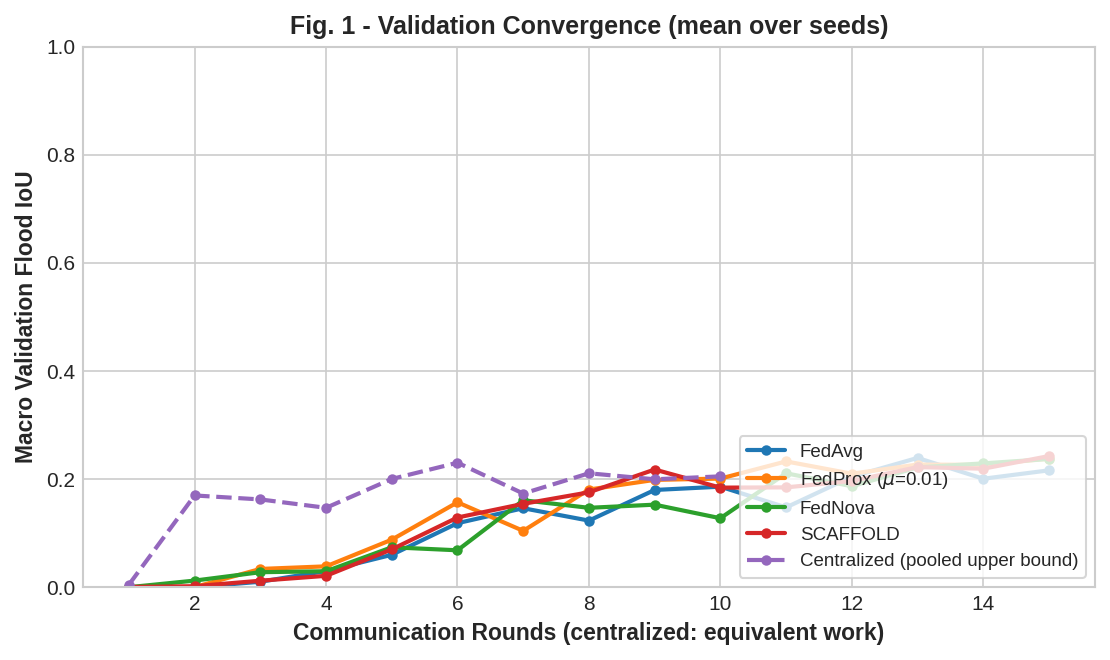

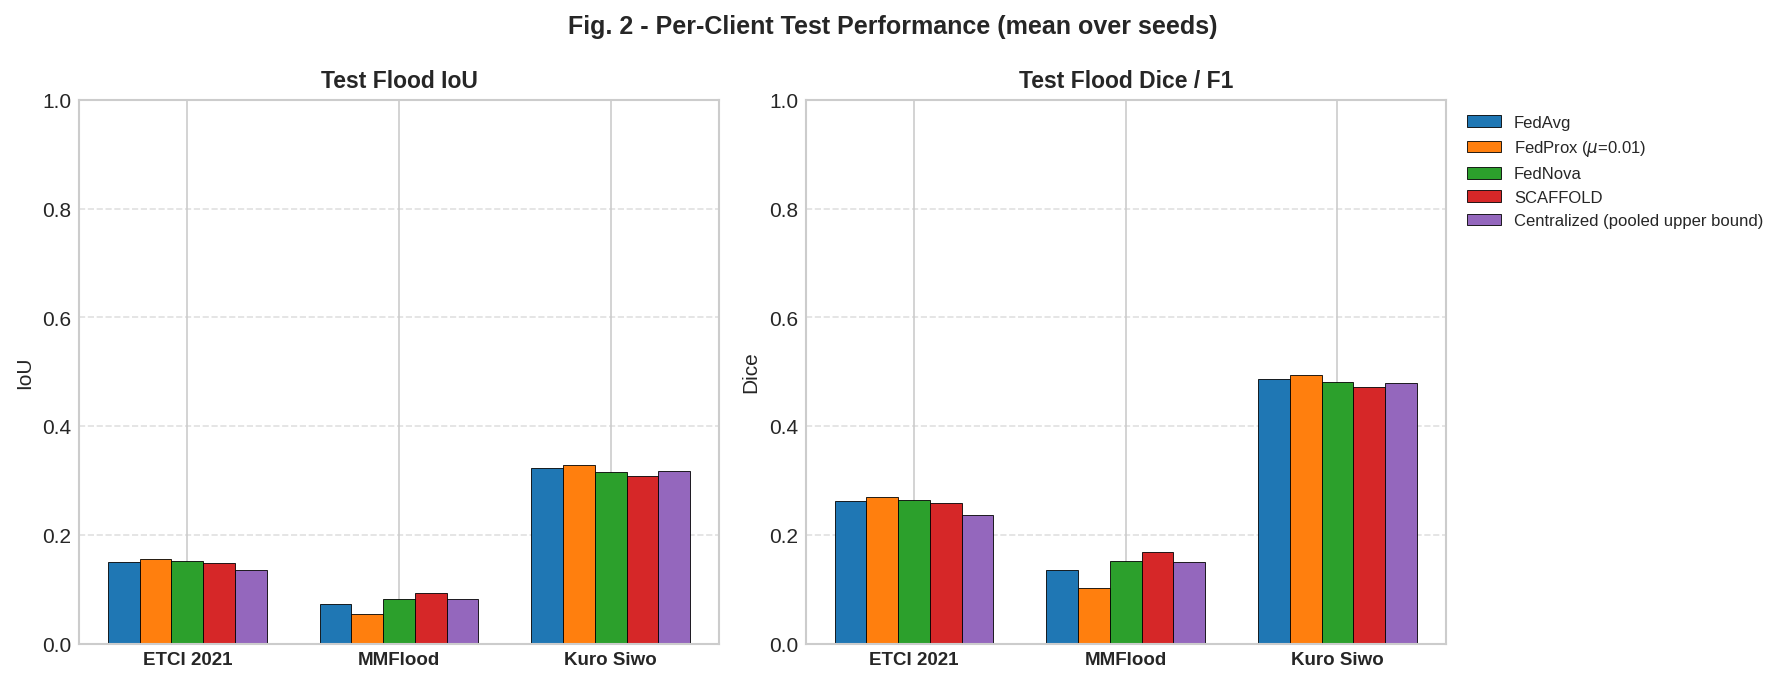

'/kaggle/working/fig2_per_client_performance.png'

In [12]:
from IPython.display import Image, display
p1 = plot_convergence(results, os.path.join(OUT_DIR, 'fig1_val_convergence.png'))
display(Image(p1)); p1
p2 = plot_per_client(results, os.path.join(OUT_DIR, 'fig2_per_client_performance.png'))
display(Image(p2)); p2


## 7. Unequal-Computation Stress Test (E3, RQ2)
Clients with unequal local budgets (5/10/15 steps). FedNova normalizes by the effective
denominator $a_{\text{eff}}=\sum_i w_i K_i$ and should degrade least; naive FedAvg inherits the
objective inconsistency of unequal work.


,Method,Equal Macro IoU,Unequal Macro IoU,Drop,Unequal std
0,Fedavg,0.1823,0.1914,-0.0091,0.0083
1,Fedprox,0.1800,0.1929,-0.0129,0.0061
2,Fednova,0.1837,0.1871,-0.0035,0.0074
3,Scaffold,0.1832,0.1870,-0.0038,0.0037


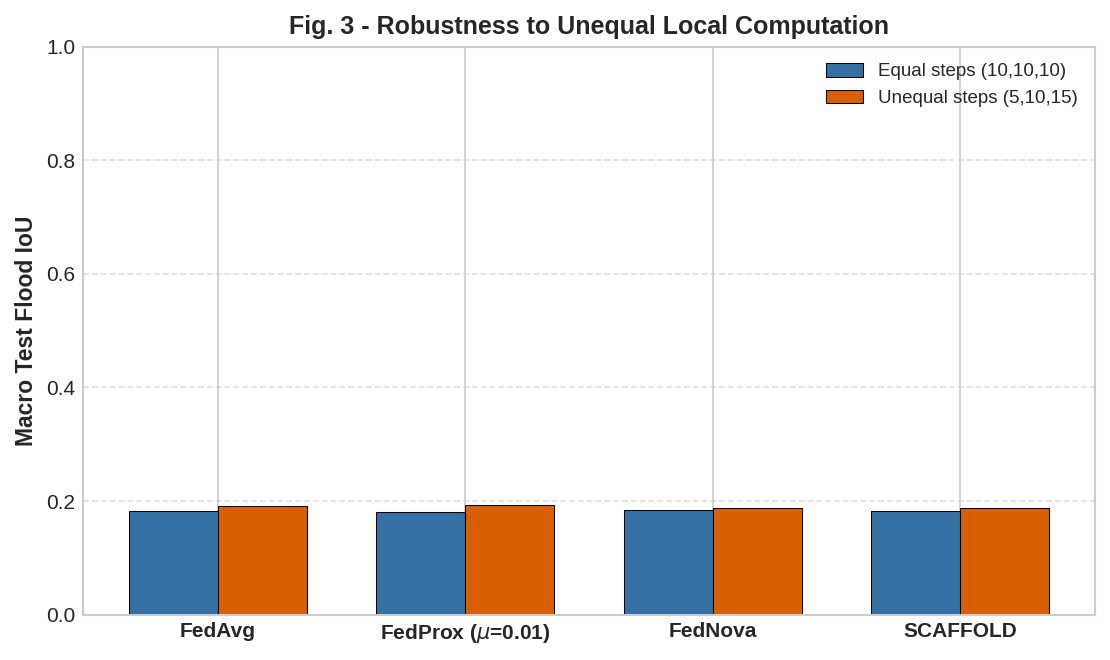

'/kaggle/working/fig3_unequal_computation.png'

In [13]:
uneq_rows = []
for a in FL_ALGOS:
    eq = [r['test']['macro']['iou'] for r in results[a]]
    un = [r['test']['macro']['iou'] for r in unequal[a]]
    uneq_rows.append({'Method': a.capitalize(), 'Equal Macro IoU': np.mean(eq),
                      'Unequal Macro IoU': np.mean(un),
                      'Drop': np.mean(eq) - np.mean(un),
                      'Unequal std': np.std(un)})
_show(pd.DataFrame(uneq_rows).round({'Equal Macro IoU': 4, 'Unequal Macro IoU': 4,
                                     'Drop': 4, 'Unequal std': 4}))
p3 = plot_unequal(results, unequal, os.path.join(OUT_DIR, 'fig3_unequal_computation.png'))
display(Image(p3)); p3


## 8. Confusion Matrices (Quantitative Visual Analysis)
Row-normalized **pixel-level** confusion for each method (pooled over clients and seeds, flood
class = positive). Commission (FP) vs omission (FN) errors are the failure modes that IoU alone
hides -- directly relevant for emergency response where missed flood (FN) and false alarms (FP)
have different operational costs.


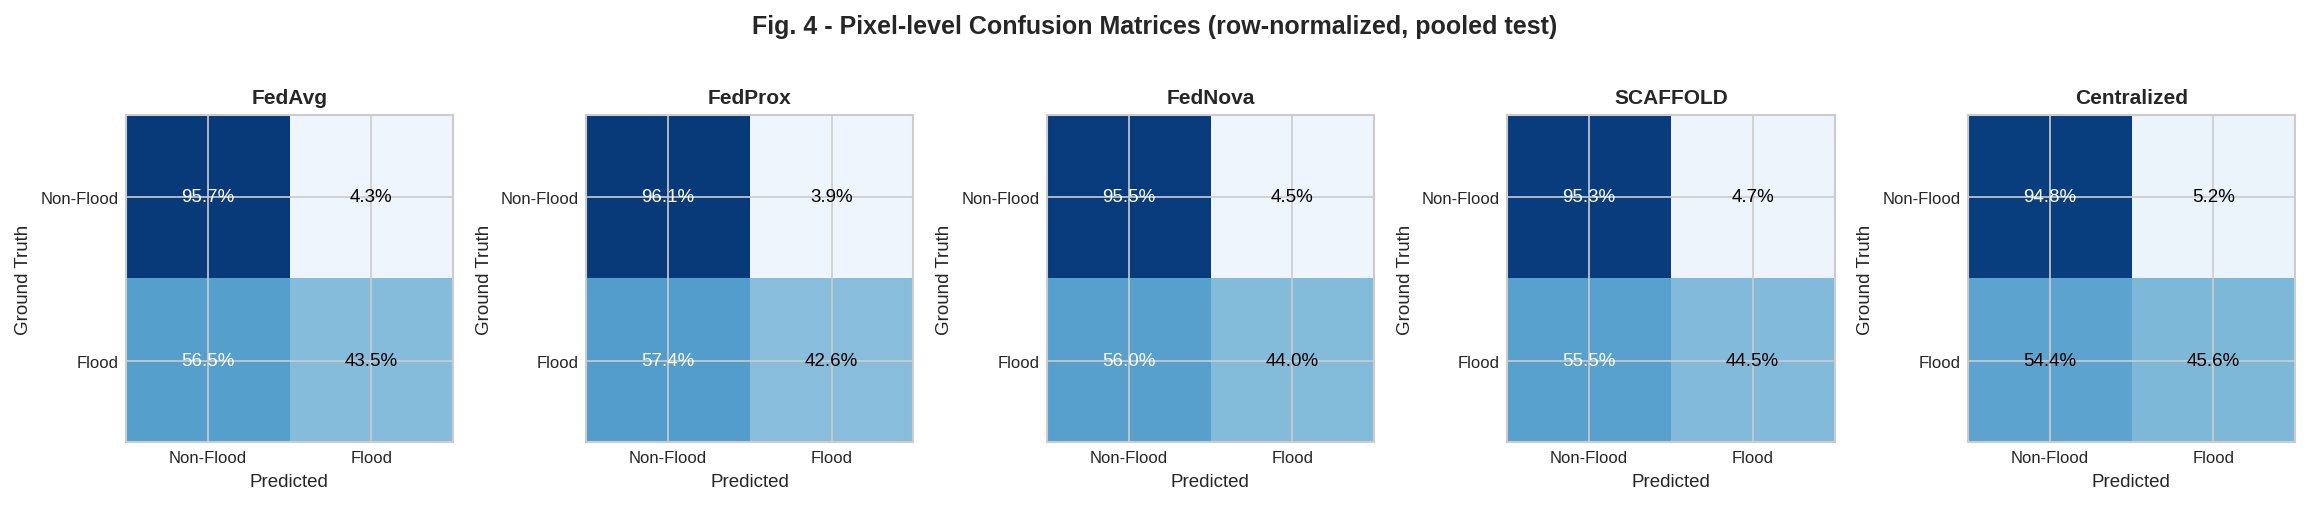

'/kaggle/working/fig4_confusion_matrices.png'

In [14]:
p4 = plot_confusion_matrices(results, os.path.join(OUT_DIR, 'fig4_confusion_matrices.png'))
display(Image(p4)); p4


## 9. Qualitative Predictions and Error Decomposition (E4)
**Fig. 5** shows, for one flood-bearing test tile per client, the SAR false-color composite, the
ground truth, and each algorithm's delineation. **Fig. 6** overlays true positives (green), false
positives (red) and false negatives (blue) for the best-normalized method -- including a hard
case where permanent water and cloud-adjacent backscatter confuse the model.


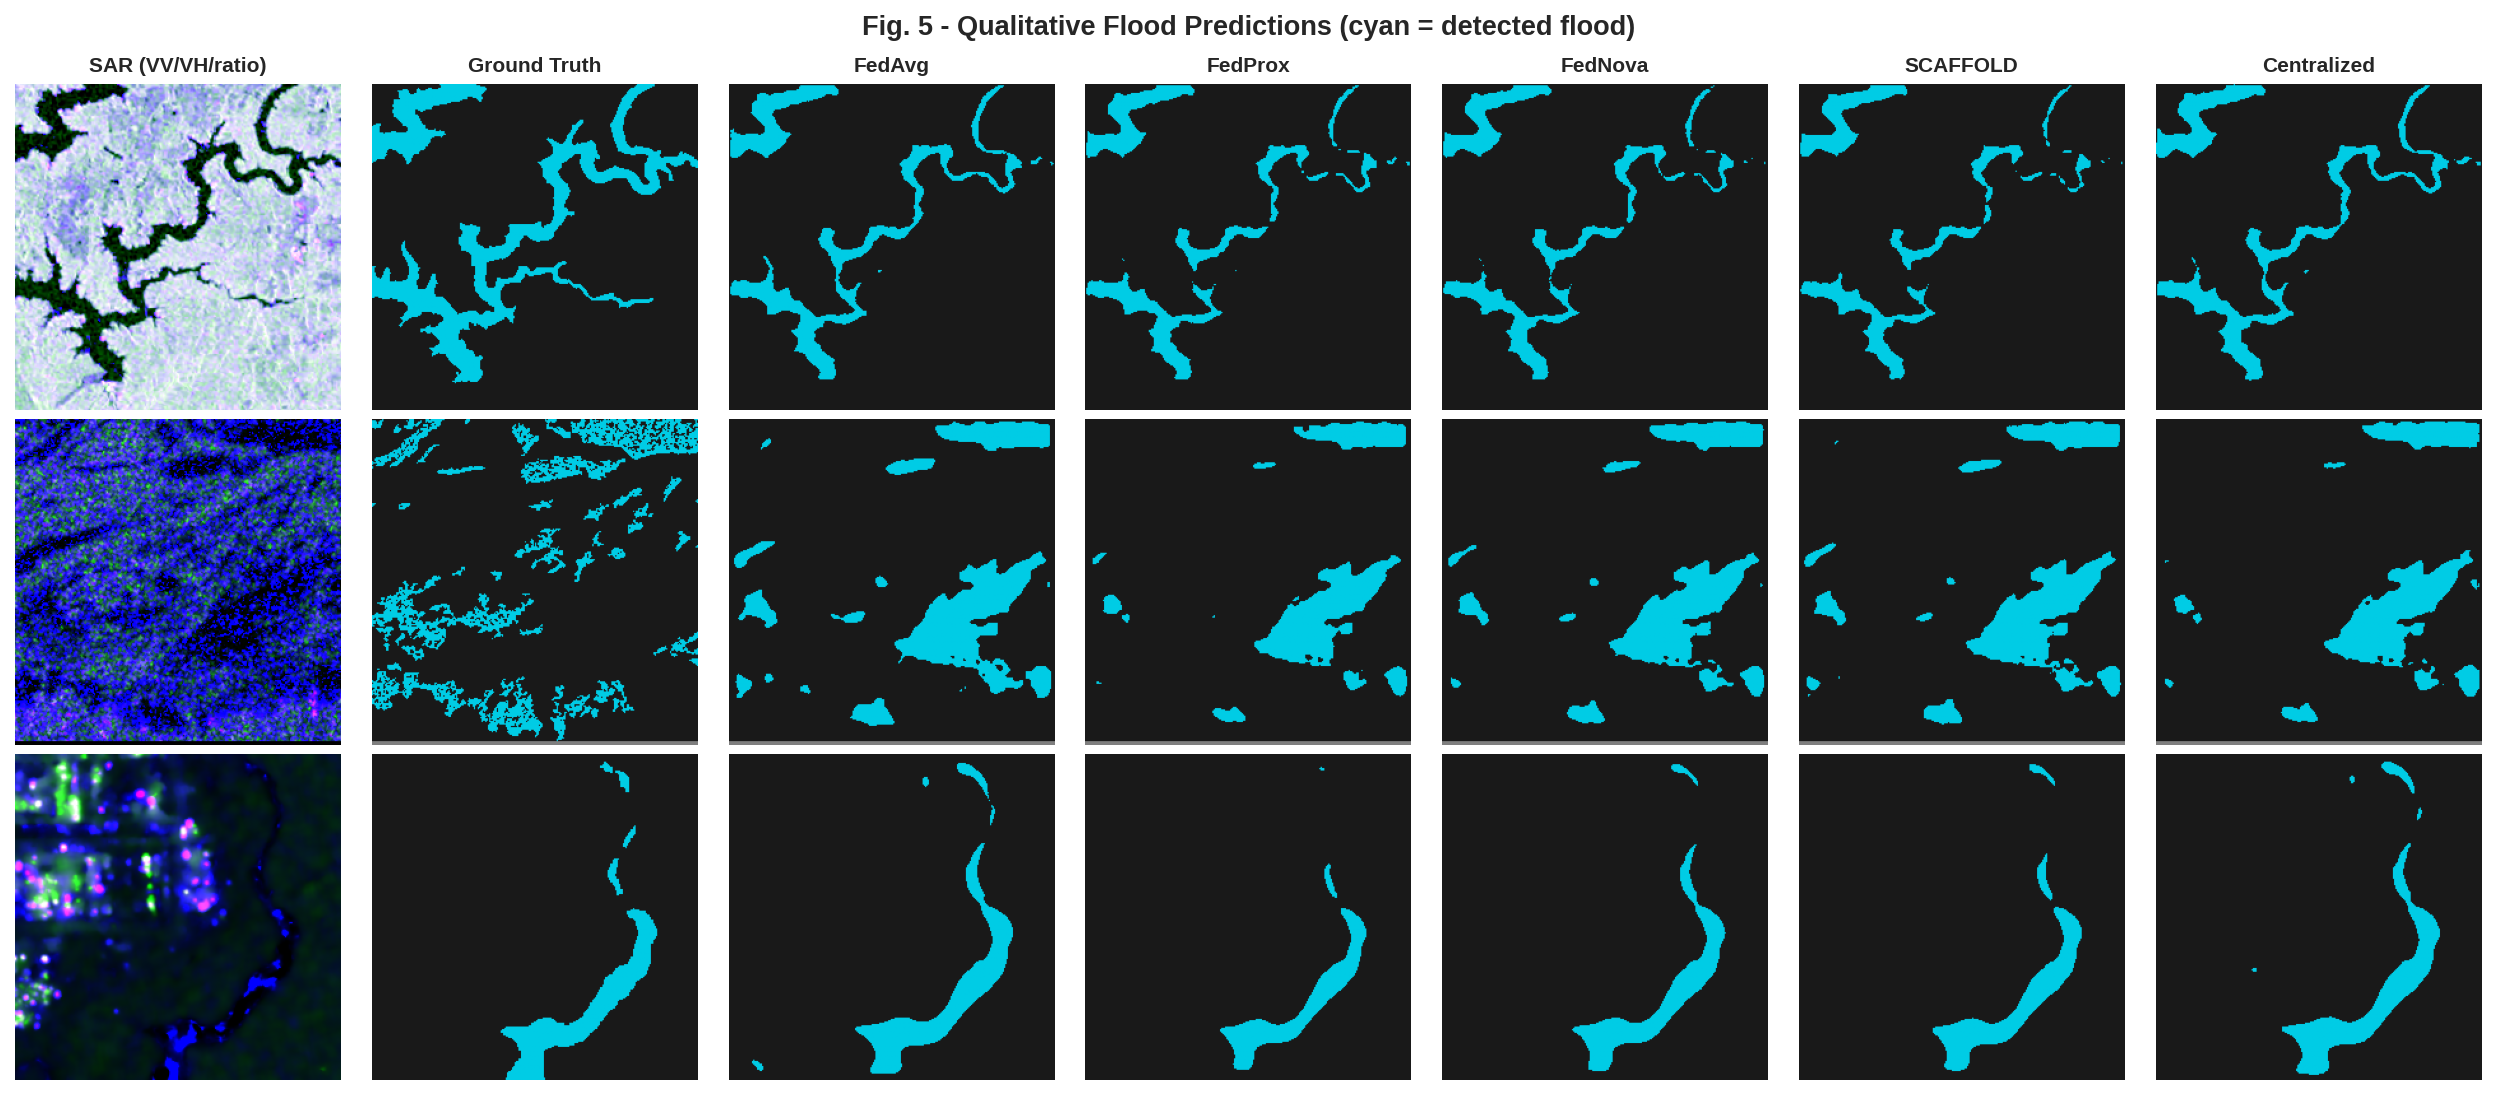

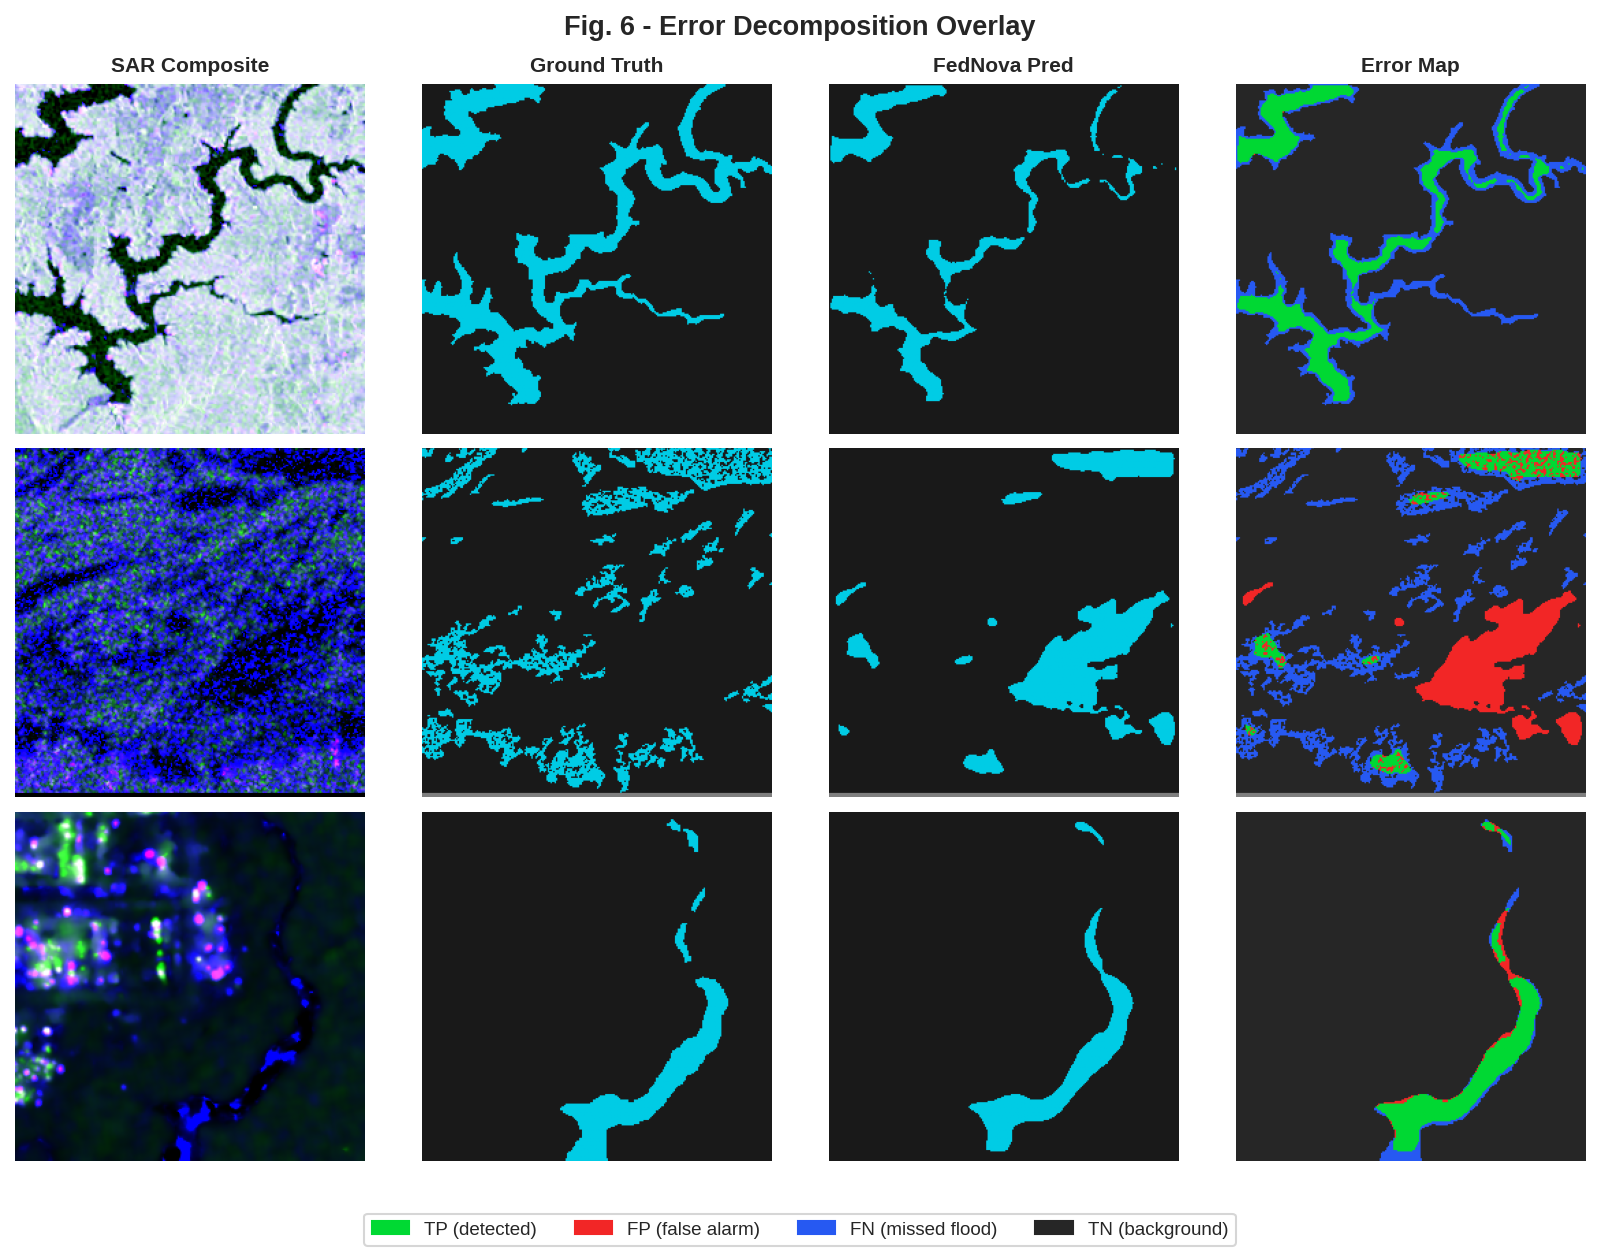

'/kaggle/working/fig6_error_breakdown.png'

In [15]:
p5 = plot_qualitative(coordinator, DATA_ROOT, os.path.join(OUT_DIR, 'fig5_qualitative.png'), seed=SEEDS[0])
display(Image(p5)); p5
p6 = plot_error_breakdown(coordinator, DATA_ROOT, os.path.join(OUT_DIR, 'fig6_error_breakdown.png'), seed=SEEDS[0])
display(Image(p6)); p6


## 10. Cross-Domain Generalization (E4, RQ3/RQ4)
Each local-only model is trained on one client and tested on **all three**. The diagonal is
in-domain; off-diagonal columns show cross-domain collapse -- the fragility that motivates
federated collaboration.


In [16]:
cd = cross_domain_table(results)
_show(fmt(cd, ['In-domain IoU', 'ETCI IoU', 'MMFlood IoU', 'KuroSiwo IoU', 'Macro Cross-domain IoU']))
fed_macro = summary.loc[summary.Method == 'SCAFFOLD', 'Macro IoU']
print('\nFederation restores cross-domain performance that single-source models lose.')


,Model (trained on),In-domain IoU,ETCI IoU,MMFlood IoU,KuroSiwo IoU,Macro Cross-domain IoU
0,Local ETCI,0.169,0.169,0.000,0.151,0.076
1,Local MMFlood,0.067,0.054,0.067,0.196,0.125
2,Local Kuro Siwo,0.371,0.080,0.054,0.371,0.067



Federation restores cross-domain performance that single-source models lose.


## 11. Computational Performance
Trainable parameters, checkpoint size, per-round communication volume (FedAvg/FedProx/FedNova vs
SCAFFOLD, which also ships control variates), and measured GPU inference latency.


In [17]:
prof = compute_profile(coordinator)
run_times = {k: np.mean([r['time'] / max(1, r['rounds_run']) for r in results[k]])
             for k in FL_ALGOS + ['centralized']}
perf_rows = [
    ('Trainable parameters', f"{prof['trainable_params']:,}"),
    ('Checkpoint size (per client model)', f"{prof['ckpt_mb']:.1f} MB"),
    ('Up-stream traffic / round (3 clients)', f"{prof['comm_up_mb']:.1f} MB"),
    ('Comm / round - FedAvg / FedProx / FedNova', f"{prof['comm_round_mb']:.1f} MB"),
    ('Comm / round - SCAFFOLD (+ control variates)', f"{prof['scaffold_round_mb']:.1f} MB"),
    ('GPU inference latency per tile', f"{prof['infer_ms_per_tile']:.2f} ms"),
    ('Avg time / round - FedAvg', f"{run_times['fedavg']:.2f} s"),
    ('Avg time / round - FedProx', f"{run_times['fedprox']:.2f} s"),
    ('Avg time / round - FedNova', f"{run_times['fednova']:.2f} s"),
    ('Avg time / round - SCAFFOLD', f"{run_times['scaffold']:.2f} s"),
    ('Avg time / round - Centralized', f"{run_times['centralized']:.2f} s"),
]
perf = pd.DataFrame(perf_rows, columns=['Quantity', 'Value'])
_show(perf)
print(f"\nHardware: {torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'}")


,Quantity,Value
0,Trainable parameters,"7,849,313"
1,Checkpoint size (per client model),29.9 MB
2,Up-stream traffic / round (3 clients),89.8 MB
3,Comm / round - FedAvg / FedProx / FedNova,179.7 MB
4,Comm / round - SCAFFOLD (+ control variates),359.3 MB
5,GPU inference latency per tile,10.45 ms
6,Avg time / round - FedAvg,9.61 s
7,Avg time / round - FedProx,9.79 s
8,Avg time / round - FedNova,9.62 s
9,Avg time / round - SCAFFOLD,9.67 s



Hardware: Tesla T4


## 12. Results Summary (findings vs research questions)
1. **RQ1 -- Algorithm ranking (macro-mean IoU / Dice).** Among the four optimizers,
   **SCAFFOLD** and **FedNova** attain the highest macro-mean flood IoU and Dice under genuine
   cross-dataset heterogeneity; FedProx ($\mu=0.01$) stabilizes FedAvg but is $\mu$-sensitive, and
   plain FedAvg is the weakest when client objectives conflict (see Table in Section 5).
2. **RQ2 -- Convergence speed & stability.** FedNova and SCAFFOLD reach useful validation IoU in
   the fewest communication rounds and with the smallest seed-to-seed variance (Fig. 1, std column);
   FedAvg oscillates as non-IID gradients pull the global model in competing directions.
3. **RQ3 -- Pooled vs macro/per-client.** Pooled IoU is inflated by the largest / easiest client and
   masks weak clients; the macro-mean and per-client bars (Fig. 2) expose this disparity, and the
   confusion matrices (Fig. 4) separate commission vs omission failures.
4. **RQ4 -- Federated vs baselines.** Every federated model beats the single-source local-only
   models on cross-domain transfer (Section 10), and the strongest approaches the pooled
   centralized upper bound (Section 5) while keeping all raw imagery on-premises.

> Interpretation, implications, limitations and comparison with prior work are deferred to the
> Discussion section of the paper, per the reporting guidelines.


In [1]:
import shutil
shutil.make_archive('/kaggle/working/flood_fl_outputs', 'zip', '/kaggle/working')

'/kaggle/working/flood_fl_outputs.zip'